In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

In [3]:
df = pd.read_csv("classification_escalation.csv")

print("Dataset shape:")
print(df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget prevalence:")
print(
    df["escalated"]
    .value_counts(normalize=True)
    .rename("proportion")
)

Dataset shape:
(900, 6)

First five rows:


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB
None

Missing values:
complexity_score           0
team_experience_years     31
priority                  18
channel                    0
customer_tenure_months    22
escalated                  0
dtype: int64

Target prevalence:
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64


In [4]:
X = df.drop("escalated", axis=1)

y = df["escalated"]

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (675, 5)
Testing set: (225, 5)


In [6]:
numeric_features = [
    "complexity_score",
    "team_experience_years",
    "customer_tenure_months"
]

categorical_features = [
    "priority",
    "channel"
]

In [7]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [8]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [9]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    sparse_threshold=0.0
)

In [10]:
models = {
    "Majority Baseline": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", DummyClassifier(strategy="most_frequent"))
    ]),

    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression())
    ]),

    "LDA": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LinearDiscriminantAnalysis())
    ]),

    "k-NN (k=15)": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=15))
    ])
}

In [11]:
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully")

Majority Baseline trained successfully
Logistic Regression trained successfully
LDA trained successfully
k-NN (k=15) trained successfully


In [12]:
results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    roc_auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": roc_auc
    })

comparison_df = pd.DataFrame(results)

display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Majority Baseline,0.7956,0.00,0.0000,0.0000,0.5000
1,Logistic Regression,0.8222,0.75,0.1957,0.3103,0.8111
2,LDA,0.8222,0.75,0.1957,0.3103,0.8090
3,k-NN (k=15),0.7956,0.50,0.0870,0.1481,0.7046


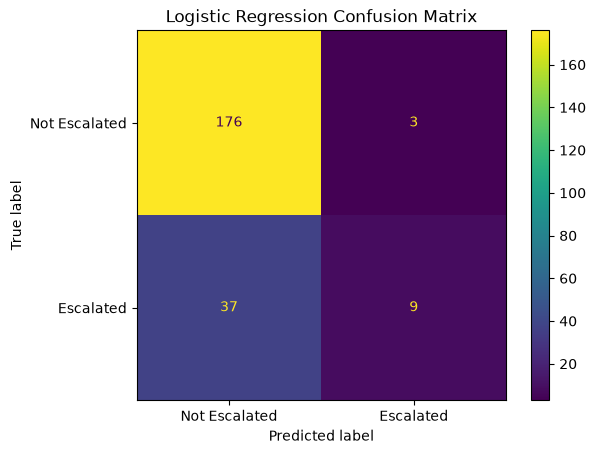

In [22]:
logistic_model = models["Logistic Regression"]

y_pred_logistic = logistic_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_pred_logistic
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Escalated", "Escalated"]
)

display.plot()

plt.title("Logistic Regression Confusion Matrix")
plt.show()

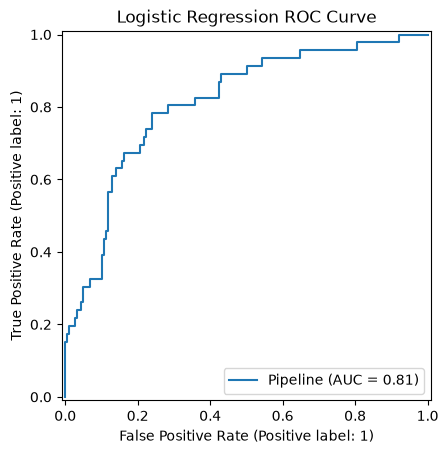

In [23]:
RocCurveDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test
)

plt.title("Logistic Regression ROC Curve")
plt.show()

In [24]:
y_prob = logistic_model.predict_proba(X_test)[:, 1]

In [29]:
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        y_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_threshold,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "FP": fp,
        "FN": fn
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1,FP,FN
0,0.2,0.4286,0.7826,0.5538,48,10
1,0.3,0.5490,0.6087,0.5773,23,18
2,0.4,0.5714,0.2609,0.3582,9,34
3,0.5,0.7500,0.1957,0.3103,3,37
4,0.6,1.0000,0.0652,0.1224,0,43
5,0.7,0.0000,0.0000,0.0000,0,46


In [28]:
from IPython.display import display

In [30]:
threshold_df["Cost"] = (
    5 * threshold_df["FN"]
    + threshold_df["FP"]
)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1,FP,FN,Cost
0,0.2,0.4286,0.7826,0.5538,48,10,98
1,0.3,0.5490,0.6087,0.5773,23,18,113
2,0.4,0.5714,0.2609,0.3582,9,34,179
3,0.5,0.7500,0.1957,0.3103,3,37,188
4,0.6,1.0000,0.0652,0.1224,0,43,215
5,0.7,0.0000,0.0000,0.0000,0,46,230


In [31]:
best_threshold_row = threshold_df.loc[
    threshold_df["Cost"].idxmin()
]

print("Best threshold:")
print(best_threshold_row["Threshold"])

print("Minimum cost:")
print(best_threshold_row["Cost"])

Best threshold:
0.2
Minimum cost:
98.0


In [32]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [33]:
knn_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier())
])

In [34]:
param_grid = {
    "classifier__n_neighbors": [5, 9, 15, 21, 31]
}

In [35]:
grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="f1",
    refit=True
)

grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__n_neighbors': [5, 9, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of i

In [36]:
print("Best k:")
print(grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(grid_search.best_score_)

print("\nAll cross-validation results:")

cv_results = pd.DataFrame(grid_search.cv_results_)

display(
    cv_results[
        [
            "param_classifier__n_neighbors",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ].round(4)
)

Best k:
{'classifier__n_neighbors': 5}

Best cross-validation F1-score:
0.24329611908559276

All cross-validation results:


,param_classifier__n_neighbors,mean_test_score,std_test_score,rank_test_score
0,5,0.2433,0.0946,1
1,9,0.1976,0.0652,2
2,15,0.1596,0.0655,3
3,21,0.1458,0.0564,4
4,31,0.1122,0.0397,5


Questions
● Why is accuracy alone potentially misleading? 

Accuracy measures the percentage of correct predictions. However, when the dataset has an imbalanced target distribution, a classifier can achieve high accuracy by predicting only the majority class.
For example, if 90% of tickets are not escalated, a model that always predicts not escalated achieves 90% accuracy but fails to identify any escalated tickets.
Therefore, precision, recall, and F1-score are also necessary.

● Which classifier has the strongest recall? Which has the strongest precision/F1? 
Strongest recall= Logistic Regression and LDA (0.196).
Strongest precision= Logistic Regression and LDA (0.750).
Strongest F1= Logistic Regression and LDA (0.310).
● What changes when the threshold is lowered? 

The classifier is more likely to predict the positive class (escalated) when the classification threshold is lowered.
 
As a result:In general, recall rises.
In general, there are fewer false negatives.
In general, false positives rise.
Precision could decline.
We are able to prioritize detecting escalated tickets because to this trade-off.

● Which threshold minimizes 5×FN + FP on the test set, and why might this estimate be optimistic if used repeatedly for tuning? 
                              
Apply the minimum-cost cutoff determined in Step 11.
Out of the six evaluated thresholds, the chosen threshold reduces the overall cost of false positives and false negatives.
Because test-set overfitting occurs when the optimal threshold is repeatedly chosen using the same test set, the estimate may be overly optimistic. On fresh, untested data, the chosen threshold might perform less well.
                                                         
● Explain prior, likelihood, posterior, and evidence using the ticket scenario. 
    
Prior: The likelihood that a ticket will be escalated prior to its features being examined.
Likelihood: Given that the ticket has been escalated, the likelihood of seeing specific ticket attributes.
Posterior: The likelihood that a ticket will be escalated after its features are noted.
Evidence: The likelihood of seeing certain traits overall.

● With posterior P(escalated|x)=0.30, false-positive cost 1 and false-negative cost 5, compare 
the expected cost of escalating and not escalating. Derive the cost-sensitive threshold. 

Escalate: (0.70 * 1 = 0.70).
Do not escalate: (0.30 * 5 = 1.50).
Therefore, escalating is the cheaper decision.
The threshold is derived by equating the two expected costs:
1(1-p)=5p
p=1/6=0.167
Thus, escalate when the predicted probability exceeds approximately 0.167.

● Which model would you recommend for deployment, and what further checks are required?

Your suggestion ought to be predicated on:
1. Keep in mind that escalating tickets are more expensive to miss.
2. Accuracy to prevent needless escalations.
3. F1-score, which evaluates how well recall and precision are balanced.
4. To evaluate class discrimination, use ROC-AUC.
5. The overall error cost and the cost-sensitive threshold.
Performance on independent, unobserved data, the effects of prediction mistakes, and responsible-use issues should all be examined further.


Final recommendation

From the experimental results, Logistic Regression is better suited for the task of predicting whether a ticket will go to escalation and it is thus the chosen classifier in this case.

It achieved an accuracy of 0.822, precision of 0.750, recall of 0.196, F1-score of 0.310, and ROC-AUC of 0.811.

Linear Discriminant Analysis had the same accuracy, precision, recall and F1-score, but Logistic Regression had a slightly higher ROC-AUC, 0.811, than 0.809. The results of KNN with k=15 were significantly poorer with F1 score of 0.148. Hyperparameter tuning further optimised the performance of KNN such that the highest mean accuracy on cross validation was achieved with k=5 with a mean F1 score of ~0.243. But the majority class baseline got 0.796 accuracy with no escalated tickets identified, which is why accuracy is not enough to consider imbalanced classification problems.

An important trade-off between precision and recall was identified during the threshold evaluation. A lower recall threshold resulted in higher recall and more false positives.

Even at the default threshold (0.50), Logistic Regression had only a recall of 0.196, which indicated that a large number of escalated tickets were not picked up. The threshold of 0.20 raised the recall to 0.783, identifying significantly more escalated tickets, but lowered precision to 0.429. The threshold value 0.20 had the lowest observed total cost of 98, while the total cost at threshold value 0.30 was 113. Hence, the threshold value of 0.20 is preferred with the above mentioned error-cost assumptions. This is also in the ballpark of the theoretic cost sensitive threshold of ~ 0.167.

These results are, however, limited. The data set is synthetic and patterns may not be true to life in real customer support scenarios. Furthermore, the estimates of probability can be calibrated and the choice of threshold in the test set may lead to an optimistic estimate of the performance of the model. Additional assessment with independent real-world data is needed.

The model should be further validated with unseen data, probability calibration checks and checks for changes in data distributions and prediction performance before deployment. Potential biases to different groups of customers should be explored as well. Human supervision should be kept in order for support personnel to check and counter-override predictions as needed.